# Wall image classification without pretrained models
## My midterm project Tasks 5 to 7

I train **Logistic Regression, Decision Tree, Random Forest and KNN** on my own BD3 dataset. Decision Tree and Random Forest both cover the tree-model requirement. No pretrained neural network or downloaded weights are used.

This notebook is the main model comparison. The extra `cnn_training.ipynb` contains a small CNN trained from random weights. Its validation protocol is separate from the five-fold classical comparison.

Install `requirements.txt`, open this notebook from the project folder, and run its cells in order. Keep `results/split_manifest.csv` and `features.py` with it. Change `DATASET` below if necessary.

In [1]:
from pathlib import Path
import json, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score
from features import extract_features

DATASET = Path("BD3_original_dataset")
if not DATASET.exists():
    DATASET = Path("/Users/daryn/Desktop/daat/BD3_original_dataset")
SEED = 42

### Data preparation

The original 3,965 images contained 61 extra same-label duplicate copies and 11 files with conflicting labels. Removing them left **3,893 unique images**. The exclusion log is `results/excluded_images.csv`. The original images are unchanged.

I reuse the recorded split to avoid repeating the longer duplicate-checking code: **3,309 development images** (the earlier training and validation subsets combined) and **584 test images**. Five-fold cross-validation happens only inside development data. The fixed test set has been evaluated in earlier project iterations, so it is a reused holdout, not a new external benchmark. There are no building IDs to guarantee that all similar scenes stay together.

In [2]:
data = pd.read_csv("results/split_manifest.csv").sort_values("path").reset_index(drop=True)
y = data.label.to_numpy()
dev = data.split.ne("test").to_numpy()
test = ~dev
print(pd.crosstab(data.label, data.split))
print("Development:", dev.sum(), "Test:", test.sum())
assert data.pixel_hash.nunique() == len(data)

split        test  train  validation
label                               
algae          92    433          93
major_crack    86    403          87
minor_crack    87    404          86
peeling        78    360          77
plain          89    412          88
spalling       75    350          75
stain          77    363          78
Development: 3309 Test: 584


### Simple image measurements

All four models receive the same **646 fixed measurements**: color histograms (96), local texture histograms (28), edge directions or HOG (324), average colors in an 8 by 8 grid (192), and overall color means and standard deviations (6). These use standard image-processing functions and learn nothing from the labels. The short implementation is in `features.py`.

Scaling for Logistic Regression and KNN is inside each pipeline, so each CV fold fits its scaler using only that fold's training images.

In [3]:
features = []
for path in data.path:
    with Image.open(DATASET / path) as image:
        features.append(extract_features(image))
X = np.array(features)
print("Feature table:", X.shape)

Feature table: (3893, 646)


## Task 5 Define and train four models

I use standard library classifiers with simple initial settings. Logistic Regression learns linear class boundaries, Decision Tree learns a sequence of rules, Random Forest combines many trees, and KNN uses nearby examples. I fit them on development data. I report test metrics after CV and tuning, so the test results cannot influence those choices.

In [4]:
models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("classifier", LogisticRegression(C=1, max_iter=2000, random_state=SEED))]),
    "Decision Tree": DecisionTreeClassifier(min_samples_leaf=2, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_features="sqrt", random_state=SEED, n_jobs=1),
    "KNN": Pipeline([("scaler", StandardScaler()), ("classifier", KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=1))])
}
fitted = {}
fit_times = {}
for name, model in models.items():
    start = time.perf_counter()
    fitted[name] = clone(model).fit(X[dev], y[dev])
    fit_times[name] = time.perf_counter() - start
print("Trained:", list(fitted))

Trained: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN']


## Task 6 Five fold cross validation

I use the same five stratified folds for every model. Each fold preserves class proportions and has its own training and validation subset. Accuracy, macro precision, macro recall, macro F1 and balanced accuracy are recorded. Macro scores give all seven classes equal weight.

I select the model with the highest **mean CV macro F1**, not the highest test accuracy. I report sample standard deviation (`ddof=1`) across the five scores. A CV fold is not part of the final test set.

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {name: name for name in ["accuracy", "precision_macro", "recall_macro", "f1_macro", "balanced_accuracy"]}
cv_results, cv_rows, fold_rows = {}, [], []
for name, model in models.items():
    scores = cross_validate(model, X[dev], y[dev], cv=cv, scoring=scoring, return_train_score=True, n_jobs=2)
    cv_results[name] = scores
    row = {"Model": name}
    for metric in scoring:
        row[metric + " mean"] = scores["test_" + metric].mean()
        row[metric + " std"] = scores["test_" + metric].std(ddof=1)
    cv_rows.append(row)
    for fold in range(5):
        fold_rows.append({"Model": name, "Fold": fold + 1, **{key: values[fold] for key, values in scores.items()}})
cv_table = pd.DataFrame(cv_rows)
print(cv_table.to_string(index=False))
pd.DataFrame(fold_rows).to_csv("results/notebook_cv_folds.csv", index=False)
cv_table.to_csv("results/notebook_cv_summary.csv", index=False)
winner = cv_table.loc[cv_table["f1_macro mean"].idxmax(), "Model"]
print("Selected by CV:", winner)

              Model  accuracy mean  accuracy std  precision_macro mean  precision_macro std  recall_macro mean  recall_macro std  f1_macro mean  f1_macro std  balanced_accuracy mean  balanced_accuracy std
Logistic Regression       0.628893      0.013196              0.623702             0.016373           0.623162          0.014209       0.622683      0.015044                0.623162               0.014209
      Decision Tree       0.558779      0.008654              0.556113             0.006811           0.553289          0.009118       0.552906      0.007467                0.553289               0.009118
      Random Forest       0.744942      0.021457              0.748268             0.023477           0.739274          0.021158       0.738473      0.021565                0.739274               0.021158
                KNN       0.611060      0.008085              0.629870             0.004789           0.601716          0.007271       0.597815      0.006612                0.60171

## Task 7 Tune at least two parameters

I use `GridSearchCV` on the winning model only. The grids below cover at least two parameters whichever model wins. The five development-data folds stay the same. The search chooses the best macro F1 and refits that setting on all development images.

For Random Forest, `max_depth` limits tree size, `min_samples_leaf` controls leaf size, and `max_features` controls how many features a split considers. The best grid score is optimistic because it was selected using these folds; this is not nested cross-validation. The held-out test comparison below is reported separately.

In [6]:
grids = {
    "Logistic Regression": {"classifier__C": [0.1, 0.3, 1, 3], "classifier__class_weight": [None, "balanced"]},
    "Decision Tree": {"max_depth": [8, 16, None], "min_samples_leaf": [1, 4]},
    "Random Forest": {"max_depth": [20, None], "min_samples_leaf": [1, 2], "max_features": ["sqrt", 0.3]},
    "KNN": {"classifier__n_neighbors": [3, 5, 9, 15], "classifier__weights": ["uniform", "distance"]}
}
search = GridSearchCV(models[winner], grids[winner], scoring=scoring, refit="f1_macro", cv=cv, n_jobs=2, return_train_score=True)
search.fit(X[dev], y[dev])
print("Best parameters:", search.best_params_)
print("CV macro F1 before:", cv_table.loc[cv_table.Model.eq(winner), "f1_macro mean"].iloc[0])
print("CV macro F1 after:", search.best_score_)
pd.DataFrame(search.cv_results_).to_csv("results/notebook_grid_search.csv", index=False)
tuned_name = winner + " (tuned)"
fitted[tuned_name] = search.best_estimator_
fit_times[tuned_name] = search.refit_time_

Best parameters: {'max_depth': 20, 'max_features': 0.3, 'min_samples_leaf': 1}
CV macro F1 before: 0.7384727513851309
CV macro F1 after: 0.7401217525719476


### Final test metrics and before and after comparison

Now that the settings are fixed, I evaluate every model on the same 584 test images. I also record development accuracy to help identify overfitting. The table includes macro precision, recall, F1 and balanced accuracy. Per-class precision, recall, F1 and support are printed below, and each confusion matrix shows actual classes on rows and predicted classes on columns.

Tuning is not guaranteed to improve every metric. I compare both the original winning model and its tuned version and report the observed changes.

In [7]:
rows, reports, predictions = [], {}, {}
for name, model in fitted.items():
    start = time.perf_counter()
    prediction = model.predict(X[test])
    elapsed = time.perf_counter() - start
    report = classification_report(y[test], prediction, output_dict=True, zero_division=0)
    reports[name], predictions[name] = report, prediction
    rows.append({"Model": name, "Accuracy": report["accuracy"], "Precision macro": report["macro avg"]["precision"],
                 "Recall macro": report["macro avg"]["recall"], "F1 macro": report["macro avg"]["f1-score"],
                 "Balanced accuracy": balanced_accuracy_score(y[test], prediction),
                 "Development accuracy": accuracy_score(y[dev], model.predict(X[dev])),
                 "Fit seconds": fit_times[name], "Predict seconds": elapsed})
    print(name, "\n", classification_report(y[test], prediction, digits=3, zero_division=0))
comparison = pd.DataFrame(rows)
print(comparison.to_string(index=False))
print("Before and after tuning:\n", comparison[comparison.Model.isin([winner, tuned_name])].to_string(index=False))
comparison.to_csv("results/notebook_test_metrics.csv", index=False)
Path("results/notebook_classification_reports.json").write_text(json.dumps(reports, indent=2))

Logistic Regression 
               precision    recall  f1-score   support

       algae      0.742     0.717     0.729        92
 major_crack      0.568     0.488     0.525        86
 minor_crack      0.529     0.529     0.529        87
     peeling      0.566     0.551     0.558        78
       plain      0.819     0.865     0.842        89
    spalling      0.653     0.653     0.653        75
       stain      0.472     0.545     0.506        77

    accuracy                          0.625       584
   macro avg      0.621     0.621     0.620       584
weighted avg      0.626     0.625     0.624       584

Decision Tree 
               precision    recall  f1-score   support

       algae      0.714     0.707     0.710        92
 major_crack      0.447     0.488     0.467        86
 minor_crack      0.449     0.460     0.455        87
     peeling      0.539     0.526     0.532        78
       plain      0.728     0.663     0.694        89
    spalling      0.611     0.587     0.

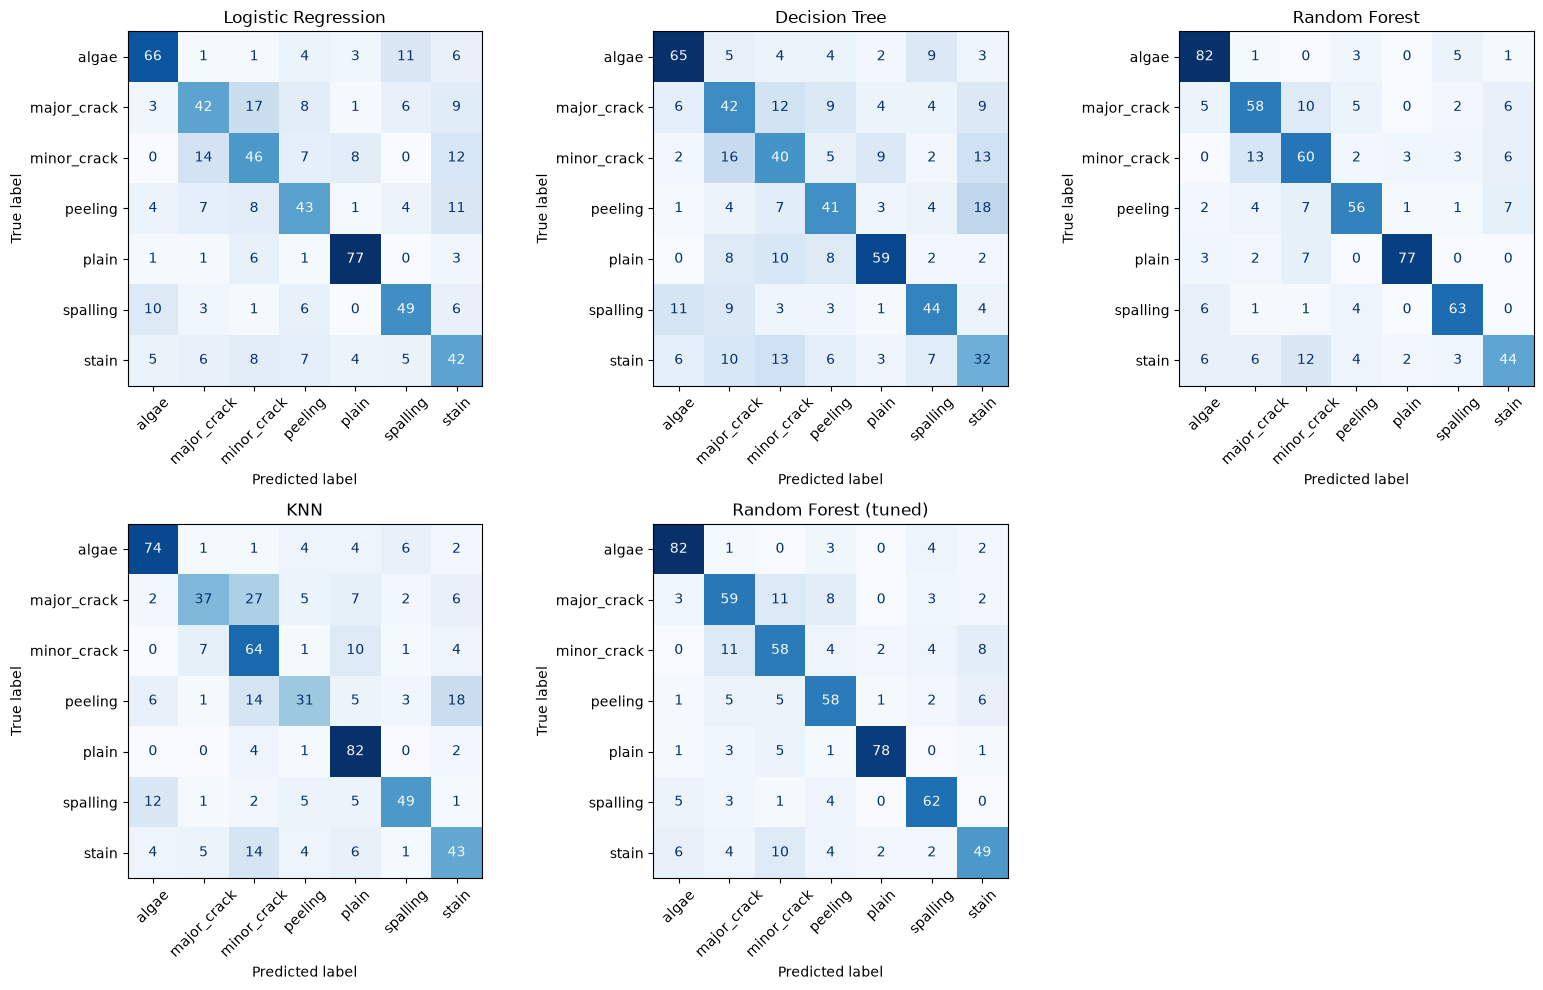

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, prediction) in zip(axes.flat, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y[test], prediction, ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(name)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.savefig("results/notebook_confusion_matrices.png", dpi=150)
plt.show()

### Save the models for the demonstration

The website uses the same image measurements and saved classifiers. Its default is the tuned winner selected through CV. A model selector also allows the other trained models and the extra scratch CNN to be tried. The app displays dataset-level test accuracy, not a promise that one particular upload is correct.

If I change the code or dataset later, I must update the Word report and combined comparison table, including the separately evaluated CNN. The notebook files beginning `notebook_` record this run's full metrics.

In [9]:
registry_path = Path("models/registry.json")
registry = json.loads(registry_path.read_text()) if registry_path.exists() else {}
for name, model in fitted.items():
    filename = name.lower().replace(" ", "_").replace("(", "").replace(")", "") + ".joblib"
    joblib.dump(model, Path("models") / filename)
    registry[name] = {"type": "classical", "file": "models/" + filename, "test_accuracy": reports[name]["accuracy"]}
registry = {tuned_name: registry[tuned_name], **registry}
registry_path.write_text(json.dumps(registry, indent=2))
print("Saved models. Start the demo with: python -m streamlit run app.py")

Saved models. Start the demo with: python -m streamlit run app.py


### Conclusion and limits

In my completed run, Random Forest had the highest baseline mean CV macro F1 (0.7385 ± 0.0216). Tuning increased CV macro F1 to 0.7401 and test accuracy from 75.34% to 76.37% (440 to 446 correct predictions out of 584). Test macro F1 increased from 0.7504 to 0.7612. The gain is modest, so I would not describe it as proof of a large improvement on new buildings.

Logistic Regression reached 62.50% test accuracy, Decision Tree 55.31%, and KNN 65.07%. Their high development scores compared with held-out scores indicate overfitting. Both Random Forest versions also fit development data perfectly, so their stronger test scores do not eliminate this concern.

I compared four classifiers, applied five-fold CV to each, and tuned the CV winner using three parameters. All learning uses my dataset; there are no pretrained weights. The extra CNN is trained separately from random initialization and is not part of this classical CV ranking.

Exact duplicates were removed, but similar scenes may remain across splits. Testing on new buildings would give a stronger estimate of real-world performance. Every upload receives one of the seven labels, even if the photo is unrelated. This is a classroom demonstration, not a building-safety assessment.

### References
- [Scikit-learn GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [Scikit-learn StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
- [Scikit-image feature functions](https://scikit-image.org/docs/stable/api/skimage.feature.html)
- Supplied local `BD3_original_dataset`.